# 00 – Einstellungen, Gebiet und Daten zuschneiden

**Ausgangslage.** Die Rohdaten liegen im Ordner `daten/roh/` (heruntergeladen einmalig mit `rohdaten_herunterladen.ipynb`). Sie werden nie verändert.

**Ziel dieses Notebooks.** Aus den Rohdaten gezielt herausholen, was wir brauchen:
1. allgemeine Einstellungen festlegen (Gebiet, Koordinatensystem, Seed, Auflösungen);
2. das **Untersuchungsgebiet** bestimmen;
3. einen **Rand von 250 m** um das Gebiet legen;
4. die Amtliche Vermessung (ganze Stadt) auf Gebiet + Rand **zuschneiden**;
5. prüfen, ob beide Luftbilder (Sommer 2024/25 und Frühjahr 2021) das Gebiet abdecken.

**Warum.** Die Rohdaten decken die ganze Stadt ab. Mit einem festen Gebiet und einem Rand rechnen alle späteren Notebooks auf demselben, kleinen Ausschnitt. Fehlt irgendwo ein Luftbild, muss das auffallen, bevor gerechnet wird.

Alle späteren Notebooks arbeiten mit diesem Ausschnitt.

**Eingaben:** Stadtkreise, Amtliche Vermessung und die Dateien beider Luftbilder in `daten/roh/`.
**Ausgaben:** `einstellungen.json` (Projektordner), `daten/verarbeitet/gebiet.geojson`, `daten/verarbeitet/bodenbedeckung_{gebiet}.gpkg`, `daten/verarbeitet/strassenstuecke_{gebiet}.gpkg`.

## 1. Allgemeine Einstellungen

Hier stehen nur die Einstellungen, die im ganzen Projekt gelten. Einstellungen, die zu einem bestimmten Schritt gehören (z. B. die Anteile der Aufteilung in Notebook 02), werden in dem Notebook festgelegt, das diesen Schritt erklärt. Jedes Notebook speichert seine Einstellungen in `einstellungen.json`, damit spätere Notebooks sie verwenden können.

In [1]:
import json                        # Einstellungen als Datei speichern
from pathlib import Path           # Pfade

KREISE = [1]                       # Untersuchungsgebiet: Stadtkreise von Zürich (1 bis 12)
                                   #   Beispiele: [1] = nur Kreis 1 (Pilot) | [2, 3] | list(range(1, 13)) = ganze Stadt
CRS = "EPSG:2056"                  # Schweizer Landeskoordinaten LV95: x und y in Metern
SEED = 42                          # Startwert für alle Zufallsgeneratoren -> jeder Lauf zieht dasselbe
AUFLOESUNGEN_CM = [5, 10]          # verglichene Auflösungen des Luftbilds (die Forschungsfrage)

# Kurzname des Gebiets für Dateinamen, z. B. "kreis1", "kreise_2_3" oder "stadt"
if KREISE == list(range(1, 13)):
    GEBIET_NAME = "stadt"
elif len(KREISE) == 1:
    GEBIET_NAME = f"kreis{KREISE[0]}"
else:
    GEBIET_NAME = "kreise_" + "_".join(str(k) for k in KREISE)

# In die Datei schreiben; Einstellungen späterer Notebooks, die schon darin stehen, bleiben erhalten
datei = Path.cwd().parent / "einstellungen.json"                     # Projektordner = eine Ebene über notebooks/
einstellungen = json.loads(datei.read_text(encoding="utf-8")) if datei.exists() else {}
einstellungen.update(KREISE=KREISE, CRS=CRS, SEED=SEED, AUFLOESUNGEN_CM=AUFLOESUNGEN_CM, GEBIET_NAME=GEBIET_NAME)
datei.write_text(json.dumps(einstellungen, indent=2, ensure_ascii=False), encoding="utf-8")
print("Gebiet:", KREISE, "→ Kurzname in Dateinamen:", GEBIET_NAME)

Gebiet: [1] → Kurzname in Dateinamen: kreis1


In [2]:
ROOT = Path.cwd().parent                       # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                   # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"        # abgeleitete Daten (jederzeit neu erzeugbar)
ORTHO_DIR = ROH / "orthofoto" / "sommer_2024_25"   # Luftbild-Kacheln
VERARB.mkdir(parents=True, exist_ok=True)

import pandas as pd                            # Tabellen
import geopandas as gpd                        # Tabellen mit Geometrie (Punkte, Linien, Flächen)
import matplotlib.pyplot as plt                # Karten
from shapely.geometry import box               # Rechteck (Kachel) aus vier Koordinaten

## 2. Sind die Rohdaten da?

In [3]:
benoetigt = ["grenzen/adm_stadtkreise_a.geojson",
             "parkplaetze/DAV_oeff_strassenparkierung_dav_p.geojson",
             "parkplaetze/DAV_oeff_strassenparkierung_dav_l.geojson",
             "vermessung/av_bo_boflaeche_a_stadt.geojson",
             "vermessung/av_geb_strassenstueck_stadt.geojson"]
pd.DataFrame({"Datei in daten/roh/": benoetigt, "vorhanden": [(ROH / d).exists() for d in benoetigt]})

,Datei in daten/roh/,vorhanden
0,grenzen/adm_stadtkreise_a.geojson,True
1,parkplaetze/DAV_oeff_strassenparkierung_dav_p....,True
2,parkplaetze/DAV_oeff_strassenparkierung_dav_l....,True
3,vermessung/av_bo_boflaeche_a_stadt.geojson,True
4,vermessung/av_geb_strassenstueck_stadt.geojson,True


## 3. Das Untersuchungsgebiet bestimmen

Die Stadtkreise sind eine Tabelle mit 12 Zeilen, jede Zeile ein Kreis als Fläche. Wir behalten die Kreise aus `KREISE`.

In [4]:
# VORHER: alle Kreise (GeoDataFrame: 1 Zeile = 1 Kreis)
kreise = gpd.read_file(ROH / "grenzen/adm_stadtkreise_a.geojson").to_crs(CRS)
# Eine Fläche ist nicht als Spalte gespeichert: .area berechnet sie aus der Geometrie (in m², weil LV95 in Metern rechnet).
# Wir legen sie als neue Spalte an, damit man sie sieht. 1 km² = 1000 m × 1000 m = 1'000'000 m².
kreise["flaeche_km2"] = (kreise.area / 1_000_000).round(2)
print("Vorher:", len(kreise), "Kreise, zusammen", round(kreise.flaeche_km2.sum(), 1), "km²")
kreise[["name", "flaeche_km2", "geometry"]]

Vorher: 12 Kreise, zusammen 91.9 km²


,name,flaeche_km2,geometry
0,6.0,5.10,"POLYGON ((2682070.921 1251415.955, 2682088.088..."
1,11.0,13.43,"POLYGON ((2678898.3 1253662.423, 2678898.55 12..."
2,12.0,5.97,"POLYGON ((2684161.525 1250427.079, 2684165.228..."
3,10.0,9.09,"POLYGON ((2677686.631 1251901.06, 2677687.451 ..."
4,4.0,2.91,"POLYGON ((2679958.008 1249151.692, 2679977.864..."
5,1.0,1.80,"POLYGON ((2682373.144 1247056.985, 2682399.474..."
6,9.0,12.06,"POLYGON ((2676224.694 1248202.542, 2676265.253..."
7,5.0,2.00,"POLYGON ((2680009.144 1249565.021, 2680055.843..."
8,7.0,15.02,"POLYGON ((2683829.509 1247953.962, 2683829.553..."
9,3.0,8.65,"POLYGON ((2678931.385 1245766.691, 2678940.133..."


In [5]:
# SCHRITT 1: Maske. kreise["name"] ist die Spalte mit der Kreisnummer; .isin(KREISE) fragt jede Zeile,
#            ob ihre Nummer in unserer Liste steht. Ergebnis: eine Spalte aus True/False.
maske = kreise["name"].isin(KREISE)
pd.DataFrame({"Kreis": kreise["name"], "in KREISE?": maske})

,Kreis,in KREISE?
0,6.0,False
1,11.0,False
2,12.0,False
3,10.0,False
4,4.0,False
5,1.0,True
6,9.0,False
7,5.0,False
8,7.0,False
9,3.0,False


In [6]:
# SCHRITT 2: Auswahl. kreise[maske] behält nur die Zeilen, bei denen die Maske True ist.
auswahl = kreise[maske]
print("Nachher:", len(auswahl), "Kreis(e)")
auswahl[["name", "flaeche_km2", "geometry"]]

Nachher: 1 Kreis(e)


,name,flaeche_km2,geometry
5,1.0,1.8,"POLYGON ((2682373.144 1247056.985, 2682399.474..."


In [7]:
# SCHRITT 3: union_all() verschmilzt die ausgewählten Kreise zu EINER Fläche.
#   Warum nicht einfach gebiet = auswahl? auswahl ist eine TABELLE (hier mit 1 Zeile), gebiet soll DIE FLÄCHE selbst sein.
#   - Bei mehreren Kreisen (z. B. [2, 3]) hätte die Tabelle mehrere Zeilen; wir wollen eine zusammenhängende Fläche.
#   - Spätere Fragen wie "berührt dieses Objekt das Gebiet?" brauchen eine einzelne Fläche; mit einer Tabelle würde
#     Python Zeile mit Zeile paaren (Zeile 0 mit Zeile 0, …) und falsche Antworten liefern.
gebiet = auswahl.union_all()
print("Vorher:", type(auswahl).__name__, "mit", len(auswahl), "Zeile(n) → nachher:", type(gebiet).__name__, "(eine Fläche)")
print("Gebiet:", round(gebiet.area), "m² =", round(gebiet.area / 1_000_000, 2), "km²")

# Speichern für alle späteren Notebooks. Dafür braucht es wieder eine Tabelle (1 Zeile: Name + Fläche).
# to_file schreibt eine Tabelle mit Geometrie in eine Datei; driver = Dateiformat (hier GeoJSON, eine Textdatei).
# VERARB ist der Ordner daten/verarbeitet/ (abgeleitete Daten); die Rohdaten in daten/roh/ bleiben unverändert.
gpd.GeoDataFrame({"gebiet": [GEBIET_NAME]}, geometry=[gebiet], crs=CRS).to_file(VERARB / "gebiet.geojson", driver="GeoJSON")

Vorher: GeoDataFrame mit 1 Zeile(n) → nachher: Polygon (eine Fläche)
Gebiet: 1800130 m² = 1.8 km²


## 4. Ein Rand von 250 m um das Gebiet

Für die Arbeit im Gebiet brauchen wir auch Daten **knapp ausserhalb**: Ein Parkfeld an der Grenze soll sein ganzes Rechteck bekommen, und die Richtung einer Strasse am Rand soll bekannt sein. Darum legen wir einen Rand von 250 m um das Gebiet.

`buffer(250)` vergrössert die Fläche in alle Richtungen um 250 m – die Form bleibt erhalten, die Ecken werden gerundet.

Gebiet 1.80 km² → mit Rand 3.58 km²


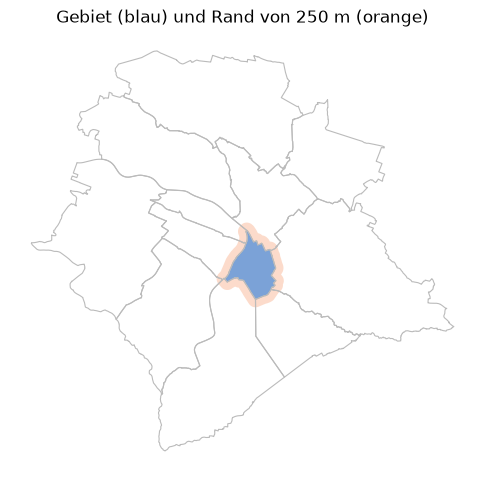

In [8]:
RAND_M = 250
rand = gebiet.buffer(RAND_M)                                   # Gebiet + 250 m in alle Richtungen
print(f"Gebiet {gebiet.area / 1e6:.2f} km² → mit Rand {rand.area / 1e6:.2f} km²")

fig, ax = plt.subplots(figsize=(6, 6))                         # leeres Blatt (fig) mit einer Zeichenfläche (ax)
kreise.boundary.plot(ax=ax, color="#bbbbbb", lw=0.8)           # Ebene 1: alle Kreise, grau
gpd.GeoSeries([rand], crs=CRS).plot(ax=ax, color="#f47230", alpha=0.25)   # Ebene 2: Rand, orange
gpd.GeoSeries([gebiet], crs=CRS).plot(ax=ax, color="#257de0", alpha=0.6)  # Ebene 3: Gebiet, blau
ax.set_title("Gebiet (blau) und Rand von 250 m (orange)")
ax.set_axis_off()                                              # Achsen mit Koordinaten ausblenden
plt.show()

## 5. Amtliche Vermessung zuschneiden

Die Vermessung liegt für die **ganze Stadt** vor. Wir behalten die Objekte, die den Rand berühren (`intersects`) – ganze Objekte, nicht abgeschnitten. Gleiches Muster wie in Abschnitt 3: Maske, dann Auswahl.

- **Bodenbedeckung:** jede Fläche mit ihrer Art (`art_txt`), z. B. Strasse, Trottoir, Gebäude. Brauchen wir für öffentliche Fläche und Privatgrund.
- **Strassenstücke:** Linien in der Mitte der Strassen. In diesem Durchgang werden sie nur in Notebook 01 angesehen: Gezählt wird je Ausschnitt, nicht je Strassenabschnitt (`01b`, Abschnitt 11, E6).

Das Lesen der ganzen Stadt dauert etwa eine Minute.

In [9]:
zugeschnitten = {}
for name, datei_roh in [("bodenbedeckung", "vermessung/av_bo_boflaeche_a_stadt.geojson"),
                        ("strassenstuecke", "vermessung/av_geb_strassenstueck_stadt.geojson")]:
    stadt = gpd.read_file(ROH / datei_roh).to_crs(CRS)          # VORHER: ganze Stadt
    im_rand = stadt.intersects(rand)                            # Maske: berührt das Objekt den Rand?
    ausschnitt = stadt[im_rand]                                 # NACHHER: nur diese Objekte
    # Speichern in daten/verarbeitet/, z. B. bodenbedeckung_kreis1.gpkg. driver="GPKG" = Dateiformat GeoPackage:
    # eine einzelne Datei (wie eine kleine Datenbank), schneller als GeoJSON und direkt in QGIS zu öffnen.
    ausschnitt.to_file(VERARB / f"{name}_{GEBIET_NAME}.gpkg", driver="GPKG")
    zugeschnitten[name] = ausschnitt
    print(f"{name}: vorher {len(stadt)} Objekte (ganze Stadt) → nachher {len(ausschnitt)} (Gebiet + Rand)")

bodenbedeckung: vorher 107135 Objekte (ganze Stadt) → nachher 6945 (Gebiet + Rand)


strassenstuecke: vorher 9969 Objekte (ganze Stadt) → nachher 1162 (Gebiet + Rand)


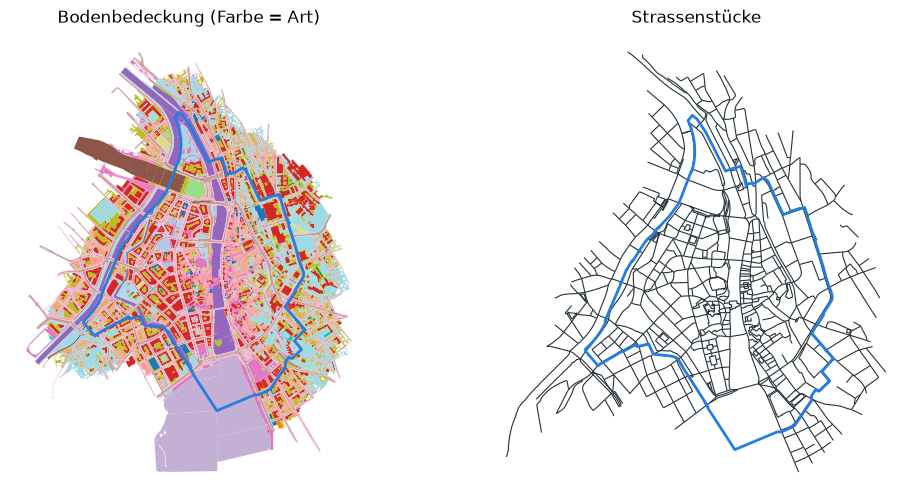

In [10]:
# Ein Blatt mit zwei Zeichenflächen nebeneinander: axs[0] links, axs[1] rechts
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

# Links: jede Fläche der Bodenbedeckung, gefärbt nach ihrer Art.
#   column="art_txt" -> die Farbe richtet sich nach dem Wert dieser Spalte (Strasse, Gebäude, Trottoir, …)
#   cmap="tab20"     -> Farbpalette mit 20 gut unterscheidbaren Farben, je Art eine
#   lw=0             -> keine Randlinien, sonst wird das Bild bei tausenden Flächen schwarz
zugeschnitten["bodenbedeckung"].plot(ax=axs[0], column="art_txt", cmap="tab20", lw=0)
axs[0].set_title("Bodenbedeckung (Farbe = Art)")

# Rechts: die Strassenstücke als dunkle Linien (lw = Liniendicke)
zugeschnitten["strassenstuecke"].plot(ax=axs[1], color="#263238", lw=0.8)
axs[1].set_title("Strassenstücke")

# In beide Bilder: der Umriss des Gebiets in Blau, Achsen ausblenden
for ax in axs:
    gpd.GeoSeries([gebiet], crs=CRS).boundary.plot(ax=ax, color="#257de0", lw=2)
    ax.set_axis_off()
plt.show()

## 6. Deckt das Luftbild das Gebiet ab?

Das Luftbild liegt in Kacheln von 1 × 1 km vor, jede Kachel eine Datei. Wir prüfen, ob die Kacheln zusammen **Gebiet und Rand vollständig bedecken**. Eine Stelle, für die keine Kachel-Datei im Ordner liegt, hat **kein Luftbild** – dort könnte das Modell später nichts erkennen. Das geht in fünf kleinen Schritten.

**Schritt 1 – Welche Bilddateien gibt es?** `ORTHO_DIR.glob("*.tif")` sucht im Luftbild-Ordner alle Dateien, deren Name auf `.tif` endet (`*` heisst: beliebiger Anfang). `sorted(...)` ordnet sie alphabetisch, damit die Reihenfolge bei jedem Lauf gleich ist.

In [11]:
dateien = sorted(ORTHO_DIR.glob("*.tif"))          # Liste der gefundenen Dateien, alphabetisch
print(len(dateien), "Dateien gefunden:")
for pfad in dateien:                                 # for: nimmt die Dateien eine nach der anderen; die aktuelle heisst "pfad"
    print("  ", pfad.name)                           # .name = Dateiname mit Endung

9 Dateien gefunden:
   2682_1246.tif
   2682_1247.tif
   2682_1248.tif
   2683_1246.tif
   2683_1247.tif
   2683_1248.tif
   2684_1246.tif
   2684_1247.tif
   2684_1248.tif


**Schritt 2 – Vom Dateinamen zur Lage, an einer Datei.** Der Name ist die linke untere Ecke in Kilometern. Wir zerlegen ihn:

In [12]:
pfad = dateien[0]                                    # die erste Datei als Beispiel
print("Dateiname ohne Endung (.stem):", pfad.stem)              # z. B. "2682_1246"
teile = pfad.stem.split("_")                                     # beim "_" trennen -> ["2682", "1246"] (Texte)
print("getrennt (.split):", teile)
x_km, y_km = int(teile[0]), int(teile[1])                        # Text -> ganze Zahl
print("als Zahlen (Kilometer):", x_km, y_km)
links, unten = x_km * 1000, y_km * 1000                          # Kilometer -> Meter: linke untere Ecke
print(f"Kachel reicht von x {links} bis {links + 1000} m und von y {unten} bis {unten + 1000} m")
quadrat = box(links, unten, links + 1000, unten + 1000)          # Quadrat aus links, unten, rechts, oben
print("als Fläche:", quadrat.area / 1_000_000, "km²")

Dateiname ohne Endung (.stem): 2682_1246
getrennt (.split): ['2682', '1246']
als Zahlen (Kilometer): 2682 1246
Kachel reicht von x 2682000 bis 2683000 m und von y 1246000 bis 1247000 m
als Fläche: 1.0 km²


**Schritt 3 – Dasselbe für alle Dateien.** Die `for`-Schleife wiederholt Schritt 2 für jede Datei und sammelt die Quadrate in einer Liste; daraus wird eine Tabelle mit Geometrie.

In [13]:
kacheln = []                                         # leere Sammelliste
for pfad in dateien:
    x_km, y_km = (int(teil) for teil in pfad.stem.split("_"))   # Schritt 2 in einer Zeile
    quadrat = box(x_km * 1000, y_km * 1000, x_km * 1000 + 1000, y_km * 1000 + 1000)
    kacheln.append(dict(kachel=pfad.stem, geometry=quadrat))     # eine Zeile: Name + Quadrat
kacheln = gpd.GeoDataFrame(kacheln, crs=CRS)                     # Liste -> Tabelle mit Geometrie
kacheln

,kachel,geometry
0,2682_1246,"POLYGON ((2683000 1246000, 2683000 1247000, 26..."
1,2682_1247,"POLYGON ((2683000 1247000, 2683000 1248000, 26..."
2,2682_1248,"POLYGON ((2683000 1248000, 2683000 1249000, 26..."
3,2683_1246,"POLYGON ((2684000 1246000, 2684000 1247000, 26..."
4,2683_1247,"POLYGON ((2684000 1247000, 2684000 1248000, 26..."
5,2683_1248,"POLYGON ((2684000 1248000, 2684000 1249000, 26..."
6,2684_1246,"POLYGON ((2685000 1246000, 2685000 1247000, 26..."
7,2684_1247,"POLYGON ((2685000 1247000, 2685000 1248000, 26..."
8,2684_1248,"POLYGON ((2685000 1248000, 2685000 1249000, 26..."


**Schritt 4 – Was ist nicht bedeckt?** Zwei Rechnungen mit Flächen:
1. `kacheln.union_all()` verschmilzt alle Kacheln zu **einer** Fläche: Überall dort haben wir ein Luftbild.
2. `rand.difference(...)` nimmt die Fläche "Gebiet + Rand" und **zieht** diese Luftbild-Fläche davon **ab**. Was übrig bleibt, ist der Teil **ohne Luftbild** (keine Kachel-Datei vorhanden).

`.area` misst diesen Rest in m². **0 m² heisst: alles bedeckt.**

In [14]:
mit_luftbild = kacheln.union_all()                   # alle Kacheln als eine Fläche: hier gibt es ein Luftbild
ohne_bild = rand.difference(mit_luftbild)            # Gebiet + Rand MINUS Luftbild-Fläche = Stellen ohne Luftbild
print("Gebiet + Rand:", round(rand.area), "m² | davon ohne Luftbild (keine Kachel):", round(ohne_bild.area), "m²")
if ohne_bild.area > 0:
    print("→ Für diese Stellen fehlen Luftbild-Kacheln im Ordner daten/roh/orthofoto/.")
    print("  Lösung: das Notebook rohdaten_herunterladen.ipynb ausführen; es lädt die fehlenden Kacheln nach.")
else:
    print("→ vollständig bedeckt: für jede Stelle von Gebiet + Rand liegt ein Luftbild vor")

Gebiet + Rand: 3578099 m² | davon ohne Luftbild (keine Kachel): 0 m²
→ vollständig bedeckt: für jede Stelle von Gebiet + Rand liegt ein Luftbild vor


**Zur Anschauung:** So sähe es aus, wenn eine Kachel fehlen würde. Wir lassen absichtlich die Kachel `2683_1247` weg (nur hier, zum Zeigen) und rechnen dasselbe noch einmal. Die rote Fläche hätte dann kein Luftbild.

Probe ohne Kachel 2683_1247: ohne Luftbild wären 1000000 m²


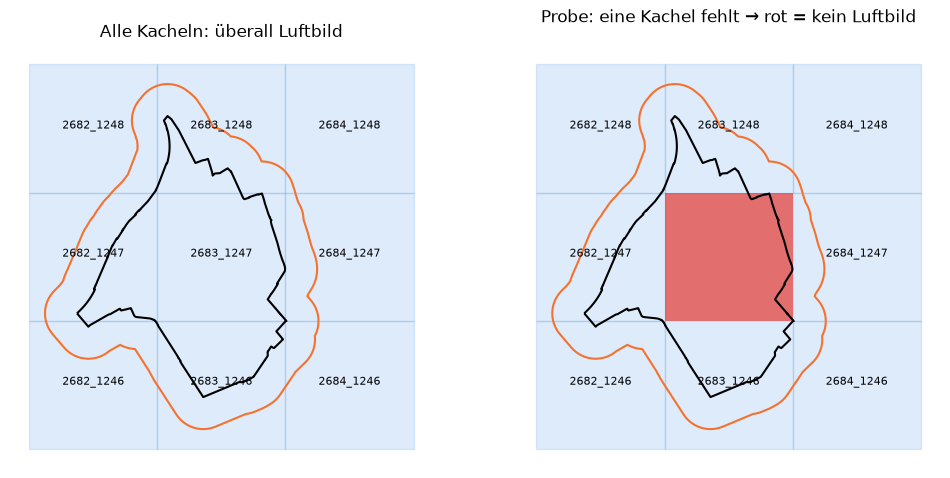

In [15]:
ohne_eine = kacheln[kacheln.kachel != "2683_1247"]                 # Tabelle ohne diese eine Kachel (Maske: alle anderen)
luecke = rand.difference(ohne_eine.union_all())                  # was dann ohne Bild bliebe
print("Probe ohne Kachel 2683_1247: ohne Luftbild wären", round(luecke.area), "m²")

# Zwei Bilder nebeneinander: links der echte Zustand, rechts die Probe mit Lücke
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, tabelle, rest, titel in [(axs[0], kacheln, ohne_bild, "Alle Kacheln: überall Luftbild"),
                                 (axs[1], ohne_eine, luecke, "Probe: eine Kachel fehlt → rot = kein Luftbild")]:
    tabelle.plot(ax=ax, color="#257de0", alpha=0.15, edgecolor="#257de0")           # Kacheln: hellblau mit Rand
    if not rest.is_empty:
        gpd.GeoSeries([rest], crs=CRS).plot(ax=ax, color="#d63031", alpha=0.7)      # Fläche ohne Luftbild: rot
    gpd.GeoSeries([rand], crs=CRS).boundary.plot(ax=ax, color="#f47230", lw=1.5)   # Rand: Umriss orange
    gpd.GeoSeries([gebiet], crs=CRS).boundary.plot(ax=ax, color="black", lw=1.5)   # Gebiet: Umriss schwarz
    for k in tabelle.itertuples():                                                 # Zeile für Zeile:
        ax.annotate(k.kachel, k.geometry.centroid.coords[0], ha="center", fontsize=8)   # Name in die Mitte schreiben
    ax.set_title(titel)
    ax.set_axis_off()
plt.show()

**Was die Abbildung zeigt.** Links der echte Zustand: Die hellblauen Kacheln bedecken das Gebiet (schwarz) und den Rand (orange) ganz. Rechts die Probe: Fehlt eine Kachel, wird die Stelle ohne Luftbild rot.

**Schritt 5 – Dasselbe für das Bild vom Frühjahr 2021.** Dieser Durchgang verwendet zwei Luftbilder (`01b`, Abschnitt 3). Die Dateien des Frühjahrsbildes sind anders geschnitten und heissen anders (z. B. `2407.tif`); ihre Lage lässt sich darum nicht aus dem Namen lesen. Wir öffnen jede Datei und lesen ihren Rahmen (`bounds`: links, unten, rechts, oben). Der Rest ist wie in Schritt 4.

Vorher: Bilddateien vom Frühjahr 2021 → nachher: Fläche von Gebiet + Rand ohne Luftbild (0 m² heisst: alles bedeckt).

In [16]:
import rasterio                                                    # Bilddateien öffnen (hier nur, um den Rahmen zu lesen)

ORTHO_DIR_2021 = ROH / "orthofoto" / "fruehjahr_2021"             # Luftbild-Dateien vom Frühjahr 2021
rahmen_2021 = []                                                   # leere Sammelliste
for pfad in sorted(ORTHO_DIR_2021.glob("*.tif")):
    with rasterio.open(pfad) as bild:                              # Datei öffnen und am Ende wieder schliessen
        rahmen_2021.append(box(*bild.bounds))                      # Rahmen der Datei als Rechteck
ohne_bild_2021 = rand.difference(gpd.GeoSeries(rahmen_2021, crs=CRS).union_all())   # Gebiet + Rand MINUS Luftbild-Fläche
print(len(rahmen_2021), "Dateien | Gebiet + Rand:", round(rand.area), "m² | davon ohne Luftbild 2021:", round(ohne_bild_2021.area), "m²")

6 Dateien | Gebiet + Rand: 3578099 m² | davon ohne Luftbild 2021: 0 m²


## Was wir gesehen haben

- Gebiet und Rand stehen fest; die Amtliche Vermessung ist darauf zugeschnitten.
- Ob beide Luftbilder Gebiet und Rand ganz bedecken, steht in den Ausgaben der Schritte 4 und 5 (0 m² heisst: alles bedeckt).

## Wie es weitergeht

Notebook 01 sieht die Rohdaten an: Parkfelder, Kanäle des Luftbilds, schwierige Stellen.